# [실습] 분류 — 확률을 예측하고 선을 긋기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 3 실습. 1,000통으로 가입을 가장 많이 얻으려면?

**필수 머신러닝 · Chapter 3**

| Part | 주제 |
| --- | --- |
| Part 1 | 데이터와 친해지기 |
| Part 2 | 현행 방법 만들기: 사람이 쓰는 선정 규칙 |
| Part 3 | 모델과 임계값 |
| Part 4 | 통화 예산 곡선과 결정 |

## 분석 의뢰서

> **의뢰 부서**: 은행 마케팅팀
> **목적**: 정기예금 상품 가입을 권유하는 전화 캠페인을 하려 한다. 가입할 가능성이 높은 고객에게 먼저 전화하고 싶다.
> **제약**: 콜센터가 이번 캠페인에 걸 수 있는 전화는 약 1,000통이다. 고객은 9,000명이 넘는다.
> **질문**: 누구에게 전화해야 가입을 가장 많이 얻을 수 있을까?

## 이 실습의 질문

> **1,000통으로 가입을 가장 많이 얻으려면 누구에게 전화해야 하는가? 그리고 전화를 2,000통으로 늘리면 가입이 얼마나 늘어나는가?**

Chapter 1, 2와 같은 순서로 진행합니다. 여러분이 먼저 마케팅팀 담당자처럼 **사람이 쓰는 선정 규칙**을 만들고, 그 규칙과 모델을 **같은 평가용 데이터**에서 비교합니다. 마지막에는 마케팅팀에 보낼 보고 메모를 씁니다.

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |

## 준비

UCI Bank Marketing 데이터의 `bank-full.csv`(통화 45,211건)를 이 노트북과 같은 폴더에 두세요. 이 파일은 열을 쉼표가 아니라 세미콜론(`;`)으로 구분합니다.

In [1]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 데이터와 친해지기

## 1-1. 데이터 불러오기

**[직접 작성]** `bank-full.csv`를 불러와 `df`에 저장하고, 행과 열의 수와 처음 5행을 확인하세요.

<details><summary>힌트</summary>

구분자가 세미콜론이므로 `pd.read_csv("bank-full.csv", sep=";")`처럼 `sep`을 알려 줘야 합니다.
</details>

In [2]:
file_path = "bank+marketing/bank-full.csv"
df = pd.read_csv(file_path, sep=";")

print("행과 열: ", df.shape)
df.head()

행과 열:  (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


원본 데이터에는 통화 시간(`duration`)이라는 열이 있습니다. 이 실습에서는 **쓰지 않습니다.** 이유는 Chapter 4에서 다룹니다. **[제공]** 셀을 실행해 이 열을 제외하세요.

In [3]:
# [제공] 통화 시간 열 제외
df = df.drop(columns=["duration"])
print(df.columns.tolist())

['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


## 1-2. 맞히려는 값 만들기

결과 열 `y`는 "yes"/"no" 글자입니다. 모델이 다룰 수 있도록 0과 1로 바꿉니다.

**[직접 작성]** 가입(`yes`)이면 1, 아니면 0인 열 `target`을 `df`에 만들고, `target`의 값별 개수와 비율을 확인하세요.

<details><summary>힌트</summary>

`df["target"] = (df["y"] == "yes").astype(int)`, 비율은 `df["target"].value_counts(normalize=True)`.
</details>

In [4]:
df["target"] = (df["y"] == "yes").astype(int)
df["target"].value_counts(normalize=True)

target
0    0.883015
1    0.116985
Name: proportion, dtype: float64

> **[판단]** "전부 미가입"이라고 답하는 방법의 정확도는 얼마인가요? 이 방법은 콜센터에 어떤 가치가 있을까요?
>
> 나의 답: 미가입 비율이 약 88.3% 이므로 전부 미가입이라고 답하는 방법의 정확도 또한 88.3%가 된다. 하지만 이 방법은 가입할 고객을 한 명도 골라내지 못해서 누구에게 전화할지는 알려주지 못한다. 따라서 정확도는 높아도 콜센터에는 가치가 없다. 

## 1-3. 데이터의 결함 찾기

**[직접 작성]** 아래 두 가지를 확인하세요.

1. `pdays`(이전 캠페인 이후 경과일)가 `-1`인 행의 비율
2. 글자로 된 열마다 `"unknown"`이라는 값이 몇 개 있는지

<details><summary>힌트</summary>

비율은 `(df["pdays"] == -1).mean()`. `"unknown"`은 `df.select_dtypes("object")`로 글자 열만 고른 뒤 `(열 == "unknown").sum()`을 세면 됩니다. 글자 열이 아닌 `target` 같은 열은 건너뜁니다.
</details>

In [5]:
print(f"pdays가 -1인 행의 비율: {(df["pdays"] == -1).mean().round(2)}")

obj_cols = df.select_dtypes("object")
print("\n글자로 된 열의 unknown 개수: ")
print((obj_cols == "unknown").sum())

pdays가 -1인 행의 비율: 0.82

글자로 된 열의 unknown 개수: 
job            288
marital          0
education     1857
default          0
housing          0
loan             0
contact      13020
month            0
poutcome     36959
y                0
dtype: int64


/var/folders/s7/_l5jm6p96nv6b0q_r6sd0g100000gn/T/ipykernel_53101/655895015.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  obj_cols = df.select_dtypes("object")


> **[판단]** `pdays`의 −1은 어떤 뜻일까요? 이 열을 숫자 그대로 모델에 넣으면 어떤 문제가 생길까요?
>
> 나의 답: -1 means client was not previously contacted -> 이전 캠페인에서 연락한 적dl 없는 고객 표시이다. 이 열을 숫자 그대로 모델에 넣을 경우 가장 최근에 연락한 고객보다 더 최근에 연락한 고객이라 취급하는 문제가 생긴다. 게다가 약 82%가 -1이라, 이 열은 연락한 적 있음/없음을 나타내는 정보에 가깝다. 

> **[판단]** `unknown`이 많은 열(`contact`, `poutcome`)은 어떻게 다루겠습니까? (예: 그대로 하나의 값으로 둔다 / 뺀다) 선택과 이유를 적으세요.
>
> 나의 답: `unknown`은 `poutcome`에 36,959개(약 82%), `contact`에 13,020개(약 29%)로 몰려 있는데, 두 열 모두 빼지 않고 `unknown`을 그대로 하나의 값으로 둔다. `poutcome`의 `unknown`은 대부분 이전 캠페인에서 연락한 적이 없는 고객이라는 뜻이어서 그 자체가 정보이고, 열을 빼면 이전 캠페인 성공 여부처럼 가입과 관련이 큰 정보까지 잃기 때문이다. `unknown`인 행을 지우는 방법은 데이터의 80% 이상이 사라지므로 쓸 수 없다.

## 1-4. 평가용 데이터 먼저 떼어 두기

Chapter 1, 2와 같은 원칙입니다. 이후의 탐색과 규칙 만들기는 **학습용 데이터만** 보고 하고, 평가용 데이터는 마지막 채점에만 씁니다.

**[직접 작성]** `df`를 학습용 80%, 평가용 20%로 나눠 `train_df`, `test_df`에 저장하세요. `random_state=42`, 그리고 가입 비율이 두 쪽에 같게 `target`으로 `stratify`합니다.

<details><summary>힌트</summary>

`train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])`
</details>

In [6]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])
print(f"train: {len(train_df):,}건\ntest: {len(test_df):,}건")


train: 36,168건
test: 9,043건


> **[판단]** 왜 가입 비율이 두 쪽에 같도록(`stratify`) 나눌까요? 가입이 11.7%뿐인 데이터를 그냥 무작위로 나누면 어떤 일이 생길 수 있나요?
>
> 나의 답: 양성(가입)이 11.7%뿐인 데이터를 무작위로 나누면 평가용에 양성이 우연히 적거나 많이 들어갈 수 있고, 그러면 같은 방법이라도 점수가 다르게 나와 평가 결과가 흔들린다. 층화 분할(stratify)은 학습용과 평가용 두 덩어리의 양성 비율을 같게 맞춰 이 흔들림을 없앤다.

### 체크포인트

여기까지 막혀서 다음으로 넘어가지 못했다면 **아래 셀만 실행**하세요. 끝낸 사람은 실행하지 않아도 됩니다.

In [7]:
# [제공] 체크포인트: 1-4까지 끝낸 사람은 실행하지 않아도 됩니다
# df = pd.read_csv("bank-full.csv", sep=";").drop(columns=["duration"])
# df["target"] = (df["y"] == "yes").astype(int)
# train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["target"])
# print(len(train_df), len(test_df))

### 실습 도구 (실행만 하세요)

| 도구 | 하는 일 |
| --- | --- |
| `rate_by(열 이름)` | 학습용 데이터에서 그 열의 값별 가입률과 통화 수를 계산한다 (숫자 열은 `bins`로 구간을 나눈다) |
| `evaluate_selection(이름, 선정 여부)` | 평가용 데이터에서 선정한 고객 수와 그중 실제 가입 수를 보여 준다 |
| `make_data(피처 목록)` | 피처 목록으로 학습용·평가용 `X`, `y`를 만든다 |
| `record(이름, 피처, 확률)` | 모델의 점수(AUC, 상위 $N$명 가입 수)를 기록표에 남긴다 |
| `run_logistic(이름, 피처, ...)` | 로지스틱 회귀를 학습하고 점수를 기록한다 |

In [8]:
# [제공] 실습 도구
y_test = test_df["target"]
base_rate = y_test.mean()
experiment_log = []
probs = {}          # 실험 이름 → 평가용 데이터의 가입 확률

def rate_by(col, bins=None):
    """학습용 데이터에서 col의 값별 가입률과 통화 수를 계산합니다. 숫자 열은 bins로 구간을 나눕니다."""
    key = pd.cut(train_df[col], bins) if bins is not None else train_df[col]
    out = train_df.groupby(key, observed=True)["target"].agg(["mean", "size"])
    out.columns = ["가입률", "통화 수"]
    return out.round(3)

def evaluate_selection(name, mask):
    """평가용 데이터에서 선정한 고객(True)을 채점합니다. (선정 수, 그중 가입 수)를 돌려줍니다."""
    mask = pd.Series(np.asarray(mask), index=test_df.index)
    n_sel = int(mask.sum()); hits = int(y_test[mask].sum()); total = int(y_test.sum())
    print(f"[{name}] 선정 {n_sel:,}명 | 그중 실제 가입 {hits}명 ({hits / n_sel * 100:.1f}%) | "
          f"무작위로 {n_sel:,}명을 골랐다면 약 {n_sel * base_rate:.0f}명 | 전체 가입 고객 {total}명 중 {hits / total * 100:.1f}%를 찾음")
    return n_sel, hits

def make_data(features):
    X = pd.get_dummies(df[features]).astype(float)
    return X.loc[train_df.index], X.loc[test_df.index], train_df["target"], test_df["target"]

def summarize(prob):
    prob = np.asarray(prob)
    ys = y_test.values[np.argsort(-prob, kind="stable")]
    return {"ROC AUC": roc_auc_score(y_test, prob), "PR AUC": average_precision_score(y_test, prob),
            "상위 1,000명 가입": int(ys[:1000].sum()), "상위 2,000명 가입": int(ys[:2000].sum())}

def record(name, features, prob):
    s = summarize(prob)
    experiment_log.append({"실험": name, "피처 수": len(features),
                           "ROC AUC": round(s["ROC AUC"], 3), "PR AUC": round(s["PR AUC"], 3),
                           "상위 1,000명 가입": s["상위 1,000명 가입"], "상위 2,000명 가입": s["상위 2,000명 가입"]})
    probs[name] = np.asarray(prob)
    print(f"기록: [{name}] ROC AUC {s['ROC AUC']:.3f} | PR AUC {s['PR AUC']:.3f} | 상위 1,000명 중 가입 {s['상위 1,000명 가입']}명")

def run_logistic(name, features, **model_kwargs):
    """피처 목록으로 로지스틱 회귀를 학습하고(스케일링 포함) 점수를 기록합니다."""
    X_tr, X_te, y_tr, _ = make_data(features)
    scaler = StandardScaler().fit(X_tr)
    model = LogisticRegression(max_iter=3000, **model_kwargs).fit(scaler.transform(X_tr), y_tr)
    prob = model.predict_proba(scaler.transform(X_te))[:, 1]
    record(name, features, prob)

## 1-5. 가입률이 높은 집단 찾기

학습용 데이터에서 "어떤 고객이 많이 가입하는가"를 찾아봅니다. 이 관찰이 Part 2에서 규칙의 재료가 됩니다. 전체 가입률은 11.7%입니다.

**[직접 작성]** `rate_by`로 다음을 확인하세요. 결과의 **통화 수**도 함께 봅니다.

- `poutcome`(이전 캠페인 결과), `contact`(연락 수단), `housing`(주택 대출), `month`(통화 월) 중 **세 개 이상**
- 나이는 구간으로: `rate_by("age", bins=[17, 25, 35, 45, 55, 65, 100])`

<details><summary>힌트</summary>

한 줄에 하나씩 `print(rate_by("열 이름"))`을 쓰세요. 결과를 가입률 순으로 보려면 `.sort_values("가입률", ascending=False)`를 붙입니다.
</details>

In [9]:
print(rate_by("poutcome").sort_values("가입률", ascending=False))
print(rate_by("contact").sort_values("가입률", ascending=False))
print(rate_by("housing").sort_values("가입률", ascending=False))
print(rate_by("month").sort_values("가입률", ascending=False))


            가입률   통화 수
poutcome              
success   0.646   1205
other     0.165   1485
failure   0.123   3889
unknown   0.092  29589
             가입률   통화 수
contact                
cellular   0.148  23465
telephone  0.139   2317
unknown    0.041  10386
           가입률   통화 수
housing              
no       0.167  15986
yes      0.077  20182
         가입률   통화 수
month              
mar    0.509    391
dec    0.472    178
sep    0.452    451
oct    0.438    592
apr    0.195   2394
feb    0.168   2078
aug    0.109   4986
jun    0.104   4237
jan    0.102   1119
nov    0.101   3143
jul    0.093   5537
may    0.067  11062


In [10]:
print(rate_by("age", bins=[17, 25, 35, 45, 55, 65, 100]))


             가입률   통화 수
age                    
(17, 25]   0.244   1079
(25, 35]   0.119  12511
(35, 45]   0.095  11098
(45, 55]   0.092   7589
(55, 65]   0.141   3282
(65, 100]  0.427    609


> **[판단]** 가입률이 전체 평균(11.7%)보다 눈에 띄게 높은 집단을 두 개 이상 적어 보세요. (예: "○○인 고객은 가입률 △△%")
>
> 나의 답: 이전 캠페인 결과(`poutcome`)가 success인 고객은 가입률 64.6%로 전체 평균의 약 5.5배이다(통화 수 1,205). 주택 대출(`housing`)이 없는 고객은 가입률이 16.7%이고 통화 수도 15986으로 많다. 3, 9, 10, 12월에 통화한 고객의 가입률도 44~51%로 높은데, 모두 통화 수가 다른 달에 비해 적다는 특징이 있다. 연령별 가입률도 차이가 컸는데, 65세 초과 고객은 42.7%(609통), 25세 이하 고객은 24.4%(1,079통)로 통화 수가 적은 집단의 가입률이 높은 경향을 보였다. 

> **[판단]** 3월의 가입률은 매우 높지만 통화 수는 매우 적습니다. 통화 수가 적은 집단의 가입률을 얼마나 믿을 수 있을까요? 규칙의 근거로 쓸 때 어떤 점을 조심해야 하나요?
>
> 나의 답: 통화 수가 적어서 몇 건의 차이로도 가입률이 크게 달라질 수 있다. 따라서 그 숫자를 그대로 믿기는 어렵다. 가입률을 규칙의 근거로 쓸 때에는 통화 수도 함께 봐서, 통화 수가 충분한 집단을 우선하고 적은 집단은 보조 조건으로만 써야 한다. 아래와 같이 추가로 통화 월을 연도별로 나눠 보니, 같은 5월도 2008년에는 가입률 3.3%(6,371통), 2010년에는 57.5%(179통)로 전혀 달랐다. 통화 수가 수천 통인 2008·2009년 5월은 가입률이 3~9%로 낮고, 350통 이하인 칸은 41~63%로 높았다(12통뿐인 2008년 12월 제외). 3·9·10·12월은 통화가 많던 2008년에 통화가 거의 없어서 가입률이 높게 집계된 것이다. 따라서 3월의 높은 가입률은 계절의 효과가 아니라 통화를 적게 걸던 시기의 효과로 보인다. `month`는 고객의 특성이 아니라 통화한 시기를 나타내므로, 다음 캠페인에서 고객을 고르는 규칙의 근거로 쓰기는 어렵다.

In [11]:
# 통화 월 × 연도별 가입률 (데이터의 행 순서 = 통화한 시간 순서)
month_order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
t = train_df.sort_index()
month_num = t["month"].map({m: i for i, m in enumerate(month_order, start=1)})
year = 2008 + (month_num < month_num.shift()).cumsum()   # 월 번호가 작아지면 해가 바뀐 것

g = t.groupby([t["month"], year.rename("연도")])["target"].agg(["mean", "size"])
cell = g.apply(lambda r: f"{r['mean']:.1%} ({int(r['size']):,}통)", axis=1)
table = cell.unstack("연도").reindex(month_order).fillna("통화 없음")
table.loc[["mar", "sep", "oct", "dec", "may"]]


연도,2008,2009,2010
month,,,
mar,통화 없음,45.9% (209통),56.6% (182통)
sep,통화 없음,43.8% (226통),46.7% (225통)
oct,62.7% (59통),42.0% (350통),41.0% (183통)
dec,8.3% (12통),50.0% (166통),통화 없음
may,"3.3% (6,371통)","9.4% (4,512통)",57.5% (179통)


---
# Part 2. 현행 방법 만들기: 사람이 쓰는 선정 규칙

여러분이 마케팅팀 담당자라고 생각해 보세요. 머신러닝 없이, 전화할 고객을 고르는 **규칙 하나**를 만들어 봅시다. 강의 Part 2에서 본 것처럼, 규칙은 "이 조건에 맞는 고객"을 고를 뿐 순위를 매기지는 못합니다. 그 한계가 실제로 무엇인지 직접 확인합니다.

## 규칙을 만들 때의 약속

- 조건은 **두세 개를 넘기지 않습니다.**
- 근거는 **1-5에서 본 집계**입니다. 평가용 데이터를 보고 규칙을 고치지 않습니다.
- 규칙은 "이 조건에 맞는 고객에게 전화한다"입니다.

## 2-1. 나의 규칙 만들기

> **[판단]** 나의 규칙(말로): 만약 **이전 캠페인 결과가 success이거나, 65세 초과이거나, 25세 이하**이면 전화한다.
>
> 이 조건을 고른 근거(1-5의 어떤 집계인가): 
>   - 이전 캠페인 결과(`poutcome`)가 success인 고객은 가입률 64.6%로 전체 평균의 약 5.5배이다(통화 수 1,205)
>   - 나이(`age`)가 65세 초과인 고객은 가입률 42.7%(통화 수 609), 25세 이하인 고객은 24.4%(통화 수 1,079)로 평균보다 높다
>
> 나의 답: 이전 캠페인 결과(`poutcome`)가 success인 고객의 가입률은 매우 높지만, 평가용 데이터는 크기가 작아 이 조건만으로는 통화 대상 고객의 수가 적을 수 있다. 따라서 가입률이 평균의 2~4배로 높은 연령 조건을 '또는'으로 추가한다. 주택 대출이 없는 고객은 가입률이 16.7%로 평균보다 조금 높은 정도이고 통화 수가 15,986으로 너무 많아, 조건에 넣으면 1,000통을 크게 넘기므로 넣지 않았다.

**[직접 작성]** 규칙을 코드로 옮겨 평가용 고객 중 선정할 고객을 `True`/`False`로 표시한 `selected`를 만드세요. 그다음 `evaluate_selection`으로 채점하고, 결과를 `rule_n, rule_hits`에 저장하세요.

<details><summary>힌트</summary>

조건은 `&`(그리고), `|`(또는)로 묶고, 조건마다 괄호를 칩니다.

```python
selected = (test_df["contact"] == "cellular") & (test_df["housing"] == "no")
rule_n, rule_hits = evaluate_selection("내 규칙", selected)
```

이 예시는 형식만 보여 주는 것입니다. 여러분의 규칙을 쓰세요.
</details>

In [12]:
# 여기에 코드를 작성하세요
# 선정 결과는 selected, 채점 결과는 rule_n, rule_hits라는 이름으로 저장하세요 (Part 4에서 다시 씁니다)
selected = (test_df["poutcome"] == "success") | (test_df["age"] > 65) | (test_df["age"] <= 25)
rule_n, rule_hits = evaluate_selection("내 규칙", selected)

[내 규칙] 선정 662명 | 그중 실제 가입 286명 (43.2%) | 무작위로 662명을 골랐다면 약 77명 | 전체 가입 고객 1058명 중 27.0%를 찾음


In [13]:
print(f"rule_n: {rule_n}\nrule_hits: {rule_hits}")

rule_n: 662
rule_hits: 286


> **[판단]** 내 규칙은 무작위로 같은 수의 고객을 골랐을 때보다 가입을 몇 배 더 얻었나요? 선정한 고객 수는 콜센터의 1,000통과 비교해 어떤가요?
>
> 나의 답: 내 규칙은 평가용 고객 중 662명을 선정했고, 그중 286명이 실제로 가입했다. 무작위로 같은 수를 골랐다면 약 77명이 가입했을 것이므로, 내 규칙은 무작위보다 가입을 약 3.7배 더 얻었다. 선정한 고객 수는 콜센터의 1,000통보다 338명 적어서, 이 규칙만으로는 통화 예산을 다 쓰지 못한다. 또 평가용 데이터의 전체 가입 고객 1,058명 중 27%만 찾았고 나머지 73%는 놓쳤다.

## 2-2. 규칙을 넓혀 1,000통을 채워 보기

콜센터는 약 1,000통을 걸 수 있습니다. 내 규칙이 고른 고객이 1,000명보다 훨씬 적다면 남는 전화는 어떻게 쓸까요? 조건을 **하나 완화**해 선정 고객을 약 1,000~2,000명으로 늘려 보세요.

**[직접 작성]** 규칙을 느슨하게 바꾼 `selected_wide`를 만들어 `evaluate_selection`으로 채점하고, 결과를 `wide_n, wide_hits`에 저장하세요. (이미 1,000명 이상을 고르는 규칙이라면 조건을 하나 추가해 줄여 보세요.)

<details><summary>힌트</summary>

예를 들어 `|`(또는)로 조건을 하나 더하면 선정이 늘고, `&`(그리고)로 조건을 하나 더하면 줄어듭니다. 나이 기준을 넓히거나, 월을 몇 개 더 포함하는 식으로 바꿔 보세요.
</details>

In [14]:
# 여기에 코드를 작성하세요
# 결과는 selected_wide, wide_n, wide_hits라는 이름으로 저장하세요

# 완화를 위한 추가 조건 : 주택 대출이 없고, 이전 캠페인에서 연락적이 있는.

selected_wide = selected | ((test_df["housing"] == "no") & (test_df["poutcome"] != "unknown"))
wide_n, wide_hits = evaluate_selection("넓힌 규칙", selected_wide)

[넓힌 규칙] 선정 1,047명 | 그중 실제 가입 381명 (36.4%) | 무작위로 1,047명을 골랐다면 약 122명 | 전체 가입 고객 1058명 중 36.0%를 찾음


In [15]:
print(f"wide_n: {wide_n}\nwide_hits: {wide_hits}")

wide_n: 1047
wide_hits: 381


In [16]:
evaluate_selection("추가된 고객만", selected_wide & ~selected)

[추가된 고객만] 선정 385명 | 그중 실제 가입 95명 (24.7%) | 무작위로 385명을 골랐다면 약 45명 | 전체 가입 고객 1058명 중 9.0%를 찾음


(385, 95)

> **[판단]** 규칙을 넓히자 선정 고객 수와 가입률이 어떻게 변했나요? "가입 가능성이 높은 순서대로 1,000명"을 규칙만으로 고를 수 있을까요? 못 한다면 이유는 무엇인가요?
>
> 나의 답: 규칙을 넓히자 선정 고객은 662명에서 1,047명으로, 가입 고객은 286명에서 381명으로 늘었다. 하지만 가입률은 43.2%에서 36.4%로 떨어졌다. 새로 추가된 고객의 가입률(24.7%)이 처음 고른 고객보다 낮기 때문이다. 
> "가입 가능성이 높은 순서대로 1,000명"은 규칙만으로 고를 수 없다. 규칙은 고객을 조건에 맞는 사람과 아닌 사람으로 나눌 뿐 순위를 매기지 못한다. 즉, 선정된 1,047명은 가입률이 높은 집단에 속한 고객을 고른 것일 뿐, 고객 한 명 한 명의 가입 가능성을 순위로 매겨 고른 것이 아니다.

---
# Part 3. 모델과 임계값

이제 모델이 **확률로 순위를 매기게** 해 봅니다. 강의 Part 1의 코드를 보지 말고 먼저 직접 써 보세요.

## 3-1. 첫 모델: 로지스틱 회귀

**[제공]** 강의에서 쓴 기본 피처 목록입니다.

In [17]:
# [제공] 기본 피처 목록 (통화 시간은 제외)
base_features = ["age", "balance", "campaign", "previous", "poutcome", "housing",
                 "loan", "contact", "month", "job", "marital", "education"]

**[직접 작성]** 아래 순서로 작성하세요.

1. `make_data(base_features)`로 `X_train, X_test, y_train, y_test`를 만든다
2. `StandardScaler`를 학습용 데이터로 학습(`fit`)하고, 학습용과 평가용에 적용(`transform`)한다
3. `LogisticRegression(max_iter=2000)`을 학습한다
4. 평가용 고객의 **가입 확률**을 `prob`에 저장한다 (`predict_proba`의 두 번째 열)

<details><summary>힌트</summary>

강의 1-6과 같은 순서입니다. 확률은 `model.predict_proba(X_test_scaled)[:, 1]`입니다.
</details>

In [18]:
# 1
X_train, X_test, y_train, y_test = make_data(base_features)

# 2
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3 로지스틱 회귀 학습
model = LogisticRegression(max_iter=2000).fit(X_train_scaled, y_train)

# 4. 평가용 고객의 가입 확률 (앞 순서 5명)
prob = model.predict_proba(X_test_scaled)[:, 1]
print(prob[:5].round(3))

[0.014 0.024 0.035 0.017 0.133]


## 3-2. 정확도는 속인다

**[직접 작성]** 임계값 0.5로 가입 여부를 예측했을 때(`pred = (prob >= 0.5).astype(int)`) 아래를 계산해 출력하세요.

- 정확도, 그리고 "전부 미가입" 베이스라인의 정확도
- 혼동행렬
- 정밀도와 재현율

<details><summary>힌트</summary>

정확도는 `(pred == y_test).mean()`, 베이스라인은 `(y_test == 0).mean()`. 나머지는 `confusion_matrix(y_test, pred)`, `precision_score(y_test, pred)`, `recall_score(y_test, pred)`입니다.
</details>

In [19]:
pred = (prob >= 0.5).astype(int)

print(f"모델 정확도: {(pred == y_test).mean():.3f}")
print(f"베이스라인(전부 미가입) 정확도: {(y_test == 0).mean():.3f}")
print("혼동행렬:")
print(confusion_matrix(y_test, pred))
print(f"정밀도: {precision_score(y_test, pred):.3f}")
print(f"재현율: {recall_score(y_test, pred):.3f}")

모델 정확도: 0.893
베이스라인(전부 미가입) 정확도: 0.883
혼동행렬:
[[7886   99]
 [ 866  192]]
정밀도: 0.660
재현율: 0.181


> **[판단]** 정확도는 베이스라인보다 얼마나 높은가요? 그런데 가입할 고객 중 모델이 찾아낸 비율(재현율)은 얼마인가요? 두 숫자가 이렇게 다른 이유를 설명해 보세요.
>
> 나의 답: 모델의 정확도는 89.3%로 베이스라인(88.3%)보다 1.0%p 높을 뿐이다. 반면 재현율은 18.1%로, 실제 가입 고객 1,058명 중 192명만 찾았다.
>두 숫자가 다른 이유는 미가입 고객이 전체의 88.3%이기 때문이다. 모델은 대부분의 고객을 미가입으로 예측해서 미가입 고객 7,886명을 맞혔고, 그래서 정확도가 높게 나온다. 정확도는 가입 고객을 얼마나 찾았는지를 거의 반영하지 못한다.
>
> | | 미가입으로 예측 | 가입으로 예측 |
> | --- | --- | --- |
> | 실제 미가입 (7,985명) | 7,886 | 99 |
> | 실제 가입 (1,058명) | 866 | 192 |


## 3-3. 임계값을 움직이면

**[직접 작성]** 임계값을 `[0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.05]`로 바꿔 가며, 임계값마다 다음을 계산해 하나의 표(`DataFrame`)로 출력하세요.

- 가입으로 예측한 고객 수
- TP(찾은 가입), FP(헛걸음), FN(놓친 가입)
- 정밀도, 재현율

<details><summary>힌트</summary>

```python
rows = []
for t in [0.5, 0.4, ...]:
    pred = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"임계값": t, "예측 가입 수": pred.sum(), "TP": tp, "FP": fp, "FN": fn,
                 "정밀도": round(tp / (tp + fp), 3), "재현율": round(tp / (tp + fn), 3)})
pd.DataFrame(rows)
```
</details>

In [20]:
rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.15, 0.1, 0.05]:
    pred = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"임계값": t, "예측 가입 수": pred.sum(), "TP": tp, "FP": fp, "FN": fn,
                 "정밀도": round(tp / (tp + fp), 3), "재현율": round(tp / (tp + fn), 3)})
pd.DataFrame(rows)


,임계값,예측 가입 수,TP,FP,FN,정밀도,재현율
0,0.50,291,192,99,866,0.660,0.181
1,0.40,443,263,180,795,0.594,0.249
2,0.30,627,347,280,711,0.553,0.328
3,0.20,1016,466,550,592,0.459,0.440
4,0.15,1596,563,1033,495,0.353,0.532
5,0.10,3440,763,2677,295,0.222,0.721
6,0.05,6650,981,5669,77,0.148,0.927


> **[판단]** 콜센터가 약 1,000통을 걸 수 있다면, 임계값을 대략 얼마로 잡으면 "가입으로 예측한 고객"이 1,000명 안팎이 되나요? 그때 정밀도와 재현율은 얼마인가요?
>
> 나의 답: 임계값을 약 0.2로 잡으면 가입으로 예측한 고객이 1,016명으로 1,000명 안밖이 된다. 이때 정밀도는 45.9%, 재현율은 44.0%이다.

> **[판단]** 전화 한 통의 비용과 가입 한 건의 가치가 모두 정해져 있다면, 임계값은 어떻게 정해야 할까요? 1,000통이라는 제약이 있을 때는 임계값을 따로 고민할 필요가 있을까요?
>
> 나의 답: 전화 한 통 비용과 가입 한 건의 가치가 정해져 있다면, 전화해서 기대되는 이익이 통화 비용보다 큰 고객에게만 전화하면 된다. 이때 기대 이익은 (가입 확률 × 가입 한 건의 가치)이므로, 임계값은 (전화 비용 / 가입 가치)로 정한다. 예를 들어, 전화 비용이 가입 가치의 10분의 1이라면, 가입 확률이 0.1 이상인 고객에게 전화하는 것이 이익이다. 그런데 1,000통이라는 제약이 있을 땐 임계값을 따로 고민할 필요가 없다. 가입 확률이 높은 순서대로 1,000명에게 전화하면 되기 때문에 임계값은 1,000번째 고객의 확률(약 0.2)로 저절로 정해진다.

## 3-4. 피처와 설정을 바꿔 보기

모델의 점수를 임계값 하나가 아니라 **임계값과 무관한 지표**로 비교합니다. 아래 `record`는 다음을 기록표에 남깁니다.

- ROC AUC, PR AUC
- 확률이 높은 순서로 1,000명(또는 2,000명)에게 전화했을 때 실제 가입한 수

**[직접 작성]** 3-1의 첫 모델을 `record("기본 모델", base_features, prob)`로 기록하세요.

In [21]:
record("기본 모델", base_features, prob)

기록: [기본 모델] ROC AUC 0.773 | PR AUC 0.411 | 상위 1,000명 중 가입 464명


**[직접 작성]** 이제 `run_logistic(이름, 피처 목록, ...)`으로 **세 번 이상** 실험하세요. 매번 점수가 자동으로 기록됩니다.

<details><summary>힌트</summary>

```python
run_logistic("월 제외", [f for f in base_features if f != "month"])
run_logistic("피처 추가", base_features + ["default", "day", "pdays"])
run_logistic("가중치 균형", base_features, class_weight="balanced")
run_logistic("규제 강화", base_features, C=0.01)
```

`C`는 작을수록 모델을 단순하게 만드는 설정입니다.
</details>

In [22]:
# 실험 1
run_logistic("월 제외", [f for f in base_features if f != "month"])

# 실험 2
run_logistic("피처 추가", base_features + ["default", "day", "pdays"])

# 실험 3
run_logistic("가중치 균형", base_features, class_weight="balanced")

# 실험 4
run_logistic("규제 강화", base_features, C=0.01)


기록: [월 제외] ROC AUC 0.754 | PR AUC 0.367 | 상위 1,000명 중 가입 403명
기록: [피처 추가] ROC AUC 0.772 | PR AUC 0.411 | 상위 1,000명 중 가입 466명
기록: [가중치 균형] ROC AUC 0.773 | PR AUC 0.409 | 상위 1,000명 중 가입 461명
기록: [규제 강화] ROC AUC 0.773 | PR AUC 0.411 | 상위 1,000명 중 가입 468명


**[제공]** 실험 기록표를 상위 1,000명 가입 수 순으로 봅니다.

In [23]:
# [제공] 실험 기록표
pd.DataFrame(experiment_log).sort_values("상위 1,000명 가입", ascending=False, kind="stable")

,실험,피처 수,ROC AUC,PR AUC,"상위 1,000명 가입","상위 2,000명 가입"
4,규제 강화,12,0.773,0.411,468,611
2,피처 추가,15,0.772,0.411,466,612
0,기본 모델,12,0.773,0.411,464,612
3,가중치 균형,12,0.773,0.409,461,613
1,월 제외,11,0.754,0.367,403,560


> **[판단]** 어떤 실험에서 점수가 가장 크게 변했나요? 반대로 피처를 더하거나 설정을 바꿔도 거의 변하지 않은 실험은 무엇인가요? 거의 변하지 않았다는 것은 무엇을 뜻할까요?
>
> 나의 답: 점수가 가장 크게 변한 것은 '월 제외' 실험으로, 상위 1,000명 가입이 464명에서 403명으로 줄었다. 반면 피처 추가, 가중치 균형, 규제 강화는 기본 모델과 2~4명 차이로 거의 변하지 않았다. 이는 그 변경이 고객의 순위를 바꾸지 못했다는 뜻이다. 추가한 피처에는 기존 피처에 없는 새로운 정보가 거의 없었고, 가중치나 규제 같은 설정은 확률의 크기만 바꿀 뿐이기 때문이다.

> **[판단]** 월(`month`)을 빼면 점수가 떨어졌습니다. 월이 가입을 설명하는 이유로 무엇을 생각할 수 있나요? 이 변수를 모델에 쓸 때 조심할 점은 무엇일까요?
>
> 나의 답: 월을 빼자 상위 1,000명 가입이 464명에서 403명으로 줄었으므로, 모델은 월에 의존하고 있었다. 월이 가입을 설명하는 이유는 계절이 아니라 통화한 시점 때문으로 보인다. 1-5에서 연도별로 나눠 보니 같은 5월도 2008년에는 가입률 3.3%, 2010년에는 57.5%였고, 통화를 적게 걸던 시기에는 어느 달이든 가입률이 높았다. 모델은 월을 통해 그런 시기의 통화를 구분한 것이다. 그래서 표면적으로는 월을 넣으면 성과가 좋아 보인다. 하지만 월은 고객의 특성이 아니라 시점에 대한 정보다. 다음 캠페인에서 전화를 걸 때는 시점이 하나로 정해져 버려서 모든 고객의 월이 같아지므로, 월로는 어떤 고객에게 전화할지 정할 수 없다. 따라서 월을 넣은 모델의 464명은 다음 캠페인에서 그대로 기대하기 어렵고, 월을 뺀 403명이 더 현실적인 기대치일 수 있다.

> **[판단]** 모델을 고를 때 ROC AUC, PR AUC, "상위 1,000명 가입 수" 중 무엇을 기준으로 삼겠습니까? 이번 의뢰서에서는 어느 쪽이 가장 직접적인가요?
>
> 나의 답: "상위 1,000명 가입 수"를 기준으로 삼겠다. 의뢰서의 질문이 "1,000통으로 가입을 가장 많이 얻으려면 누구에게 전화해야 하는가"이므로, 이 지표가 가장 직접적이다. ROC AUC와 PR AUC는 전화하지 않을 고객들의 순위까지 포함해 평가하는 지표라서, 보조로만 참고하겠다.

---
# Part 4. 통화 예산 곡선과 결정

이제 질문으로 돌아옵니다. **1,000통으로 가입을 가장 많이 얻으려면 누구에게 전화해야 하는가? 전화를 2,000통으로 늘리면 가입이 얼마나 늘어나는가?**

## 4-1. 상위 $N$명 표 만들기

**[직접 작성]** 3-4의 기록표에서 "상위 1,000명 가입"이 가장 많은 실험을 골라 그 이름을 `best_name`에 저장하고, 그 확률을 `best_prob`에 저장하세요. 그다음 확률이 높은 순서로 고객을 정렬해, 평가용 고객의 실제 가입 여부를 그 순서대로 늘어놓은 `y_sorted`를 만드세요.

<details><summary>힌트</summary>

각 실험의 확률은 `probs`에 이름으로 저장되어 있습니다. `best_name = "기본 모델"`처럼 이름을 적고 `best_prob = probs[best_name]`로 꺼냅니다.

정렬 순서는 `order = np.argsort(-best_prob)`, 정렬된 가입 여부는 `y_sorted = y_test.values[order]`.
</details>

In [24]:
best_name = "규제 강화"
best_prob = probs[best_name]

order = np.argsort(-best_prob)        # 확률이 높은 순서
y_sorted = y_test.values[order]       # 그 순서대로 늘어놓은 실제 가입 여부
print(y_sorted[:20])

[0 1 1 1 0 1 1 1 1 1 0 1 0 1 1 1 0 0 0 1]


**[직접 작성]** 전화 수 $N$이 500, 1,000, 2,000, 3,000일 때 각각

- 확률 상위 $N$명 중 실제 가입 수
- 가입률
- 무작위로 $N$명을 골랐을 때의 기대 가입 수와 모델이 몇 배 더 얻는지

를 표로 출력하세요.

<details><summary>힌트</summary>

`y_sorted[:N].sum()`이 상위 $N$명 중 가입 수입니다. 무작위 기대 가입 수는 `N * base_rate`입니다. (`base_rate`는 도구 셀에서 만들어 둔 전체 가입률입니다.)
</details>

In [25]:
rows = []
for N in [500, 1000, 2000, 3000]:
    hits = int(y_sorted[:N].sum())
    rows.append({"전화 수": N, "모델 가입 수": hits, "가입률": round(hits / N, 3),
                 "무작위 기대 가입 수": round(N * base_rate), "배수": round(hits / (N * base_rate), 2)})
pd.DataFrame(rows)


,전화 수,모델 가입 수,가입률,무작위 기대 가입 수,배수
0,500,290,0.580,58,4.96
1,1000,468,0.468,117,4.00
2,2000,611,0.305,234,2.61
3,3000,720,0.240,351,2.05


## 4-2. 예산 곡선 그리기

**[직접 작성]** 상위 몇 명까지 전화했을 때 **누적 가입 수**가 얼마인지를 `cum_model`에 저장하세요. (`y_sorted`를 누적해서 더한 값입니다.)

<details><summary>힌트</summary>

`cum_model = np.cumsum(y_sorted)`. `cum_model[999]`가 1,000통을 걸었을 때의 가입 수입니다. (순서는 0부터 세므로 1,000번째는 999번입니다.)
</details>

In [26]:
cum_model = np.cumsum(y_sorted)
print(f"1,000통: {cum_model[999]}명, 2,000통: {cum_model[1999]}명")

1,000통: 468명, 2,000통: 611명


**[제공]** 모델의 곡선과 무작위, 그리고 Part 2의 내 규칙(두 점)을 한 그래프에 그립니다.

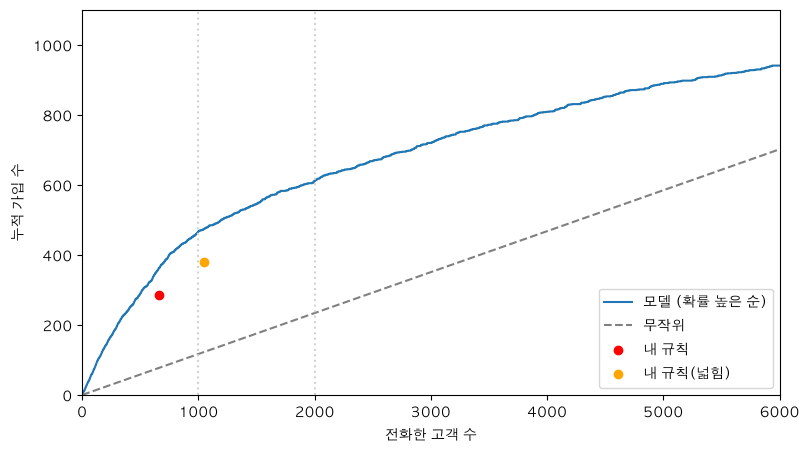

In [27]:
# [제공] 통화 예산 곡선
N_all = len(y_sorted)
x = np.arange(1, N_all + 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, cum_model, label="모델 (확률 높은 순)")
ax.plot(x, x * base_rate, linestyle="--", color="gray", label="무작위")
ax.scatter([rule_n], [rule_hits], color="red", zorder=5, label="내 규칙")
ax.scatter([wide_n], [wide_hits], color="orange", zorder=5, label="내 규칙(넓힘)")
for N in (1000, 2000):
    ax.axvline(N, color="lightgray", linestyle=":")
ax.set_xlim(0, 6000)
ax.set_ylim(0, 1100)
ax.set_xlabel("전화한 고객 수")
ax.set_ylabel("누적 가입 수")
ax.legend()
plt.show()

> **[판단]** 내 규칙의 두 점은 모델의 곡선과 비교해 어디에 있나요? 규칙을 넓혔을 때 점이 곡선에서 멀어졌나요, 가까워졌나요?
>
> 나의 답: 내 규칙의 두 점은 모두 무작위 선보다는 훨씬 위에 있지만 모델의 곡선보다는 아래에 있다. 내 규칙은, 넓힌 규칙 모두 곡선보다 아래인데, 넓힌 규칙이 좀 더 곡선에서 떨어져 있다.

## 4-3. 같은 수를 고른다면

규칙과 모델을 공정하게 비교하려면 **같은 수의 고객**을 골라야 합니다. 규칙이 `rule_n`명을 골랐다면, 모델도 상위 `rule_n`명만 고르면 됩니다.

**[직접 작성]** 모델이 확률 상위 `rule_n`명, 그리고 `wide_n`명을 골랐을 때 얻는 가입 수를 `model_at_rule`, `model_at_wide`에 저장하고, 규칙의 가입 수(`rule_hits`, `wide_hits`)와 나란히 출력하세요.

<details><summary>힌트</summary>

`cum_model[rule_n - 1]`입니다. ($N$명을 골랐을 때의 가입 수는 `cum_model`의 $N$번째 값입니다.)
</details>

In [28]:
model_at_rule = int(cum_model[rule_n - 1])
model_at_wide = int(cum_model[wide_n - 1])

print(f"내 규칙   {rule_n:,}명 선정 → 규칙 {rule_hits}명 | 모델 {model_at_rule}명 | 차이 {model_at_rule - rule_hits}명 ({model_at_rule / rule_hits:.2f}배)")
print(f"넓힌 규칙 {wide_n:,}명 선정 → 규칙 {wide_hits}명 | 모델 {model_at_wide}명 | 차이 {model_at_wide - wide_hits}명 ({model_at_wide / wide_hits:.2f}배)")


내 규칙   662명 선정 → 규칙 286명 | 모델 363명 | 차이 77명 (1.27배)
넓힌 규칙 1,047명 선정 → 규칙 381명 | 모델 474명 | 차이 93명 (1.24배)


> **[판단]** 같은 수의 고객을 골랐을 때 모델이 내 규칙보다 가입을 몇 명 더(몇 배) 얻었나요? 규칙을 넓혔을 때 그 차이는 어떻게 달라졌나요?
>
> 나의 답: 같은 662명을 골랐을 때 모델은 363명으로 내 규칙(286명)보다 77명 더(1.27배) 얻었다. 규칙을 넓힌 1,047명에서는 모델이 474명으로 규칙(381명)보다 93명 더(1.24배) 얻었다. 규칙을 넓히자 차이가 명수로는 77명에서 93명으로 커졌고, 배수로는 1.27배에서 1.24배로 비슷했다.

## 4-4. 전화를 늘리면 가입은 얼마나 느는가

전화를 한 통씩 더 걸 때마다 얻는 가입은 줄어듭니다. 이 감소가 예산을 정하는 핵심입니다.

**[직접 작성]** 전화 수를 1,000 간격(1,000, 2,000, …, 6,000)으로 늘려 갈 때, **직전 구간보다 추가로 건 전화 1통당 얻는 가입 수**(추가 가입률)를 표로 출력하세요.

<details><summary>힌트</summary>

구간 `[a, b)`의 추가 가입 수는 `cum_model[b - 1] - cum_model[a - 1]`이고, 추가로 건 전화는 `b - a`통입니다. 첫 구간(0~1,000)은 `cum_model[999]`를 그대로 씁니다.
</details>

In [29]:
rows = []
prev = 0
for b in range(1000, 7000, 1000):
    total = int(cum_model[b - 1])
    before = int(cum_model[prev - 1]) if prev > 0 else 0
    rows.append({"구간": f"{prev:,}~{b:,}", "누적 가입 수": total, "추가 가입 수": total - before,
                 "추가 가입률": round((total - before) / (b - prev), 3)})
    prev = b
pd.DataFrame(rows)


,구간,누적 가입 수,추가 가입 수,추가 가입률
0,"0~1,000",468,468,0.468
1,"1,000~2,000",611,143,0.143
2,"2,000~3,000",720,109,0.109
3,"3,000~4,000",809,89,0.089
4,"4,000~5,000",889,80,0.080
5,"5,000~6,000",941,52,0.052


**가정**: 전화 한 통의 비용이 10달러이고, 가입 한 건이 은행에 주는 가치가 100달러라고 해 봅시다. (실제 값이 아니라 이 실습을 위한 가정입니다.) 이 경우 전화 한 통이 본전이 되려면 가입률이 **10% 이상**이어야 합니다.

> **[판단]** 위 가정이라면 어느 구간까지 전화를 걸어야 이득일까요? 표의 "추가 가입률"이 10% 밑으로 떨어지는 구간을 찾아 몇 통까지 걸지 정하고 이유를 적으세요. (1,000통이라는 제약은 잠시 잊습니다.)
>
> 나의 답: 3,000통까지 거는 것이 이득이다. 추가 가입률은 01,000통 구간 46.8%, 1,0002,000통 14.3%, 2,0003,000통 10.9%로 본전인 10%보다 높지만, 3,0004,000통 구간에서 8.9%로 10% 밑으로 떨어진다. 이 구간부터는 전화 1,000통의 비용(10,000달러)이 얻는 가입의 가치(8,900달러)보다 커서 손해다. 다만 2,000~3,000통 구간은 10.9%로 본전을 겨우 넘는 수준이다.

> **[판단]** 의뢰서에는 1,000통이라는 제약이 있습니다. 위 가정에서 1,000통은 너무 적을까요, 충분할까요? 마케팅팀에 "통화 예산을 늘릴 만한가"를 어떻게 설명하겠습니까?
>
> 나의 답: 위 가정에서는 1,000통이 너무 적다. 1,000통을 더 걸어 2,000통으로 늘리면 가입이 143명 늘어난다. 추가 비용은 10,000달러이고 추가 가입의 가치는 14,300달러이므로 4,300달러가 남는다. 마케팅팀에는 "가입 가능성이 높은 순서대로 걸면 2,000통까지는 전화할수록 이익이 늘어난다. 2,000통에서 3,000통 사이는 109명이 더 가입해 900달러가 남는 정도라 거의 본전이고, 3,000통을 넘기면 손해다"라고 설명하겠다. 단, 이 결론은 전화 비용 10달러, 가입 가치 100달러라는 가정에 따른 것이라 실제 값이 다르면 달라진다.

## 4-5. 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 틀려도 괜찮습니다. 예상이 빗나간 지점이 가장 많이 배우는 곳입니다.

전화할 고객을 고르는 규칙은 나의 규칙 하나만 있는 것이 아닙니다. 다음 절에서는 1-5의 집계에서 본 조건들로 만들 수 있는 규칙을 모두 만들어 채점합니다. 조건은 성격이 다른 두 종류입니다.

| 종류 | 조건 | 특징 |
| --- | --- | --- |
| 강한 조건 | 이전 캠페인 성공(`poutcome` = success), 60세 초과, 25세 이하 | 해당 고객은 200~300명뿐이지만 가입률이 22~65%로 높다 |
| 넓은 조건 | 휴대전화 연락(`contact` = cellular), 주택 대출 없음(`housing` = no), 통화 2회 이하(`campaign` ≤ 2), 잔액 1,000 이상(`balance` ≥ 1,000) | 해당 고객이 수천 명이지만 가입률이 13~17%로 낮다 |

그래서 규칙도 두 가족으로 만듭니다. 2-1의 나의 규칙과 2-2의 넓힌 규칙이 바로 이 두 가족입니다.

- **좁은 규칙**: 강한 조건을 1~3개 "또는"으로 모은다 → 3 + 3 + 1 = 7개. 적은 인원을 고른다.
- **넓은 규칙**: 넓은 조건을 1~4개 "그리고"로 좁힌다 → 4 + 6 + 4 + 1 = 15개. 많은 인원을 고른다.

규칙마다 고르는 인원이 다르므로, 공정하게 비교하려면 **같은 인원을 고른 모델**과 비교합니다(4-3). 규칙이 625명을 골랐다면 모델도 확률 상위 625명을 고릅니다. 이때 규칙이 얻은 가입이 모델의 몇 %인지를 **규칙의 효율**이라고 부르겠습니다.

> **[판단]** 예상 ① 규칙 22개 중, 같은 인원을 골랐을 때 모델보다 가입을 더 많이 얻는(효율 100% 이상) 규칙이 있을까요? 있다면 어느 가족의 규칙일까요?
>
> 나의 답: 모델을 이기는 규칙은 없거나, 있어도 좁은 규칙 1개 정도일 것이다. 모델은 규칙에 쓰인 조건을 모두 피처로 갖고 있어서, 조건을 몇 개만 쓰는 규칙이 넘기는 어렵다. 가능성이 있다면 이전 캠페인 성공을 쓰는 경우이다. 

> **[판단]** 예상 ② 좁은 규칙과 넓은 규칙 중 어느 가족의 효율이 더 높을까요? 이유도 적어 보세요.
>
> 나의 답: 효율은 좁은 규칙이 더 높다. 가입률이 매우 높은 조건을 쓰기 때문이다. 

## 4-6. 규칙 22개 채점하기

**[직접 작성]** `my_rule_text`에 나의 규칙을 한 줄로 적으세요. 아래 결과에서 나의 규칙을 표시할 때 씁니다. (예: `"이전 캠페인 성공 또는 60세 초과"`)

In [30]:
my_rule_text = "이전 캠페인 성공 또는 65세 초과 또는 25세 이하"

**[제공]** 좁은 규칙 7개와 넓은 규칙 15개를 만들고, 규칙마다 같은 인원을 고른 모델의 가입 수와 비교합니다.

In [31]:
# [제공] 좁은 규칙(강한 조건을 "또는"으로)과 넓은 규칙(넓은 조건을 "그리고"로)
from itertools import combinations

strong = {
    "이전 캠페인 성공": test_df["poutcome"] == "success",
    "60세 초과": test_df["age"] > 60,
    "25세 이하": test_df["age"] <= 25,
}
broad = {
    "휴대전화 연락": test_df["contact"] == "cellular",
    "주택 대출 없음": test_df["housing"] == "no",
    "통화 2회 이하": test_df["campaign"] <= 2,
    "잔액 1,000 이상": test_df["balance"] >= 1000,
}

candidates = []
for n in [1, 2, 3]:
    for combo in combinations(strong, n):
        candidates.append(("좁은 규칙", " 또는 ".join(combo), np.logical_or.reduce([strong[c] for c in combo])))
for n in [1, 2, 3, 4]:
    for combo in combinations(broad, n):
        candidates.append(("넓은 규칙", " 그리고 ".join(combo), np.logical_and.reduce([broad[c] for c in combo])))

rows = []
for family, name, mask in candidates:
    n_sel = int(mask.sum())
    hits = int(y_test[np.asarray(mask)].sum())
    model_hits = int(cum_model[n_sel - 1])
    rows.append({"가족": family, "규칙": name, "선정 인원": n_sel, "규칙 가입": hits,
                 "규칙 가입률": round(hits / n_sel, 3), "모델 가입 (같은 인원)": model_hits,
                 "효율": round(hits / model_hits, 2)})
rules = pd.DataFrame(rows).sort_values("효율", ascending=False, ignore_index=True)
print("만든 규칙 수:", len(rules))
rules

만든 규칙 수: 22


,가족,규칙,선정 인원,규칙 가입,규칙 가입률,모델 가입 (같은 인원),효율
0,좁은 규칙,이전 캠페인 성공,306,199,0.650,203,0.98
1,넓은 규칙,휴대전화 연락,5820,888,0.153,930,0.95
2,좁은 규칙,이전 캠페인 성공 또는 60세 초과,484,265,0.548,283,0.94
3,넓은 규칙,통화 2회 이하,6000,798,0.133,941,0.85
4,넓은 규칙,휴대전화 연락 그리고 통화 2회 이하,3910,677,0.173,802,0.84
5,넓은 규칙,주택 대출 없음,4095,679,0.166,816,0.83
6,넓은 규칙,휴대전화 연락 그리고 주택 대출 없음,2987,586,0.196,720,0.81
7,좁은 규칙,이전 캠페인 성공 또는 60세 초과 또는 25세 이하,727,312,0.429,389,0.80
8,좁은 규칙,이전 캠페인 성공 또는 25세 이하,549,246,0.448,310,0.79
9,넓은 규칙,주택 대출 없음 그리고 통화 2회 이하,2643,516,0.195,684,0.75


**[제공]** 규칙들의 점을 모델의 곡선 위에 그리고, 나의 규칙과 비교합니다.

효율 100% 이상(모델 이상)인 규칙: 0개 / 22개
나의 규칙 [이전 캠페인 성공 또는 65세 초과 또는 25세 이하] 662명 선정 → 가입 286명 | 모델 같은 인원 → 가입 363명 | 효율 0.79
  나보다 효율이 높은 규칙: 9개

가족별 효율 중앙값:
가족
넓은 규칙    0.63
좁은 규칙    0.79
Name: 효율, dtype: float64

선정 인원이 700~1,500명인 규칙 (1,000통 제약에 가까운 규칙)
   가족                                                규칙  선정 인원  규칙 가입  규칙 가입률  모델 가입 (같은 인원)   효율
좁은 규칙                     이전 캠페인 성공 또는 60세 초과 또는 25세 이하    727    312   0.429            389 0.80
넓은 규칙                          주택 대출 없음 그리고 잔액 1,000 이상   1459    325   0.223            540 0.60
넓은 규칙              휴대전화 연락 그리고 주택 대출 없음 그리고 잔액 1,000 이상   1053    269   0.255            476 0.57
넓은 규칙              휴대전화 연락 그리고 통화 2회 이하 그리고 잔액 1,000 이상   1329    284   0.214            520 0.55
넓은 규칙             주택 대출 없음 그리고 통화 2회 이하 그리고 잔액 1,000 이상    951    244   0.257            452 0.54
넓은 규칙 휴대전화 연락 그리고 주택 대출 없음 그리고 통화 2회 이하 그리고 잔액 1,000 이상    703    205   0.292            379 0.54


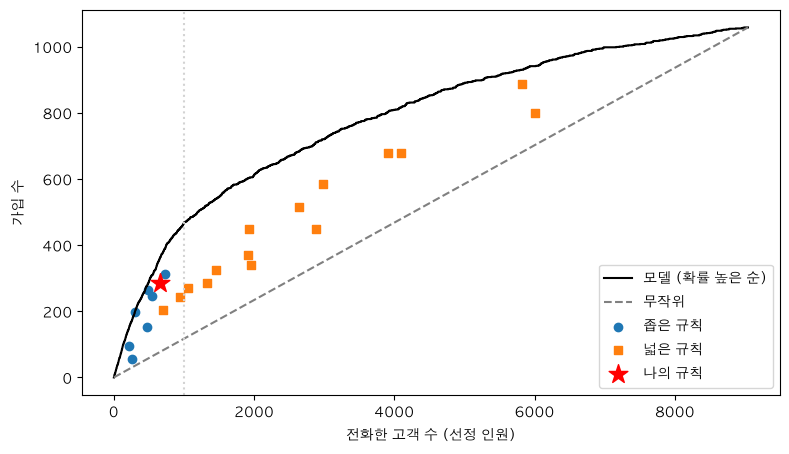

In [32]:
# [제공] 규칙들과 모델의 곡선
my_eff = rule_hits / cum_model[rule_n - 1]
print(f"효율 100% 이상(모델 이상)인 규칙: {(rules['효율'] >= 1).sum()}개 / {len(rules)}개")
print(f"나의 규칙 [{my_rule_text}] {rule_n:,}명 선정 → 가입 {rule_hits}명 | 모델 같은 인원 → 가입 {int(cum_model[rule_n - 1])}명 | 효율 {my_eff:.2f}")
print(f"  나보다 효율이 높은 규칙: {(rules['효율'] > my_eff).sum()}개")
print()
print("가족별 효율 중앙값:")
print(rules.groupby("가족")["효율"].median())
print()
print("선정 인원이 700~1,500명인 규칙 (1,000통 제약에 가까운 규칙)")
print(rules[rules["선정 인원"].between(700, 1500)].to_string(index=False))

x = np.arange(1, len(y_sorted) + 1)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, cum_model, color="black", label="모델 (확률 높은 순)")
ax.plot(x, x * base_rate, linestyle="--", color="gray", label="무작위")
for family, marker in [("좁은 규칙", "o"), ("넓은 규칙", "s")]:
    part = rules[rules["가족"] == family]
    ax.scatter(part["선정 인원"], part["규칙 가입"], marker=marker, label=family)
ax.scatter([rule_n], [rule_hits], color="red", s=200, marker="*", zorder=5, label="나의 규칙")
ax.axvline(1000, color="lightgray", linestyle=":")
ax.set_xlabel("전화한 고객 수 (선정 인원)")
ax.set_ylabel("가입 수")
ax.legend(loc="lower right")
plt.show()

## 4-7. 결과를 본 뒤

> **[판단]** 예상 ①, ②는 맞았나요? 가장 크게 빗나간 것은 무엇이고, 왜 빗나갔다고 생각하나요?
>
> 나의 답: 예상1은 맞았다. 모델을 이기는 규칙은 없었고,  가장 가까운 것은 "이전 캠페인 성공"(효율 0.98)이었다. 예상 2는 좁은 규칙의 효율 중앙값이 0.79, 넓은 규칙이 0.63으로 결론은 맞았지만, "가입률이 높은 조건을 쓰기 때문"이라는 이유는 빗나갔다. 좁은 규칙인 "25세 이하"는 효율이 0.33으로 꼴찌였고, 가입률이 15.3%뿐인 넓은 규칙 "휴대전화 연락"은 0.95로 2위였다. 효율은 규칙의 가입률만이 아니라 같은 인원을 고른 모델과의 비교로 정해지는데, 이 점을 놓쳤다. 적은 인원을 고를 때는 모델의 가입률이 매우 높아 이기기 어렵고, 수천 명을 고를 때는 누가 골라도 결과가 비슷해진다.

> **[판단]** 좁은 규칙과 넓은 규칙의 효율은 어떻게 다른가요? 그림에서 두 가족의 점이 모델의 곡선과 얼마나 떨어져 있는지와 연결해 설명해 보세요. 넓은 규칙에 조건을 "그리고"로 더할수록 효율은 어떻게 변하나요?
>
> 나의 답: 효율 중앙값은 좁은 규칙이 0.79, 넓은 규칙이 0.63이다. 그림에서 "이전 캠페인 성공"이 들어간 좁은 규칙은 곡선 바로 아래에 붙어 있다. 넓은 규칙은 수천 명을 고를 때는 곡선에 가깝지만 인원이 줄수록 멀어진다. 조건을 "그리고"로 더할수록 효율은 떨어진다(1개일 때 최고 0.95, 4개일 때 0.54). 조건을 더해도 규칙의 가입률은 조금 오르는데, 같은 인원에서 모델의 가입률은 훨씬 빨리 오르기 때문이다.

> **[판단]** 1,000통 제약에 가까운 규칙(선정 700~1,500명)은 가입을 몇 명 얻나요? 같은 인원을 고른 모델과 비교하면 몇 배인가요? 마케팅팀이 규칙 대신 모델을 쓸 이유가 충분한가요?
>
> 나의 답: 선정 인원이 700~1,500명인 규칙 6개는 가입을 205~325명 얻었고, 같은 인원을 고른 모델은 379~540명으로 1.25~1.85배다. 모델을 쓸 이유는 충분하다. 같은 통화 수로 가입을 더 얻고, 정확히 1,000명을 고를 수 있기 때문이다.

> **[판단]** 나의 규칙은 규칙들 사이에서 어디쯤인가요? 좁은 규칙과 넓은 규칙을 "또는"으로 합치면(예: 이전 캠페인 성공 또는 주택 대출 없음 그리고 잔액 1,000 이상) 선정 인원과 효율이 어떻게 될지 예상해 보세요. 이렇게 규칙을 손으로 조합해 가는 일과, 모델이 확률로 순서를 매기는 일은 무엇이 다른가요?
>
> 나의 답: 나의 규칙은 효율 0.79로 22개 중 9개가 나보다 높아 중상위다. 좁은 규칙과 넓은 규칙을 "또는"으로 합치면 선정 인원은 늘고 효율은 두 규칙의 사이가 될 것이다. 규칙은 조합마다 하나씩 채점해 봐야 하고 선정된 고객 안에서 순위를 매기지 못한다. 모델은 모든 조건을 한꺼번에 반영해 고객마다 확률을 매기므로, 순서대로 원하는 인원만큼 자를 수 있다.

## 4-8. 마케팅팀 보고 메모

분석 결과를 마케팅팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **누구에게 전화해야 하는가**: 선정 방식(예: 가입 가능성이 높은 순서대로 $N$명)을 한 문장으로 쓴다
2. **예산별 기대 가입**: 1,000통과 2,000통일 때 기대할 수 있는 가입 수를 쓰고, 현재 쓰는 방법(내 규칙)과 비교한다
3. **권고**: 몇 통을 걸 것을 권하는지, 4-4에서 가정한 비용 구조를 밝히고 이유를 쓴다
4. **주의할 점**: 통화 시간 열을 뺀 이유를 아직 확인하지 못했다는 것(Chapter 4 예고), 통화 수가 적은 집단 규칙의 불확실성, 이 데이터는 2008~2010년 포르투갈 은행의 것이라는 점

> **[판단]** 마케팅팀 보고 메모:
>
> 1. 선정 방식: 고객마다 가입 가능성을 점수로 계산해, 점수가 높은 순서대로 전화합니다.
>
> 2. 예산별 기대 가입 (평가에 쓴 고객 9,043명 기준)
>    - 1,000통: 가입 468명
>    - 2,000통: 가입 611명
>    - 현재 방식과 비교: 현재 방식은 662통으로 286명을 얻었습니다. 같은 662통을 점수 순서로 걸면 363명으로 77명이 많습니다.
>
> 3. 권고와 이유: 통화 예산을 2,000통으로 늘리시길 권합니다.
>    - 가정: 전화 한 통 10달러, 가입 한 건의 가치 100달러
>    - 1,000통 → 2,000통: 비용 10,000달러, 추가 가입 143명(14,300달러)으로 4,300달러가 남습니다.
>    - 2,000통 → 3,000통: 추가 가입 109명으로 900달러가 남아 거의 본전입니다.
>    - 3,000통 초과: 손해입니다.
>
> 4. 주의할 점
>    - 통화 시간 정보는 분석에서 뺐는데, 그 이유는 아직 확인하지 못했습니다.
>    - 위 숫자는 통화한 달 정보를 포함한 결과입니다. 다음 캠페인은 한 시점에 걸기 때문에 이 정보를 쓸 수 없고, 이를 빼면 1,000통 기준 가입이 403명으로 줄어듭니다.
>    - 통화 수가 적은 집단(65세 초과, 25세 이하)의 가입률은 그대로 믿기 어렵습니다.
>    - 이 데이터는 2008~2010년 포르투갈 은행의 것이어서 지금 우리 고객과 다를 수 있습니다.
>
> 나의 답: 점수 순서로 2,000통을 거는 것을 권합니다.


---
# 마무리

## 이 Chapter의 판단 포인트

> **놓친 가입 고객과 헛걸음한 전화 중 무엇이 더 비싼가? 임계값은 모델이 아니라 비용이 정한다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 줄을 내 말로 적으세요.

예: "분류 모델의 점수를 보면 임계값과 혼동행렬을 먼저 묻고, 같은 수를 고른 현행 규칙과 비교한다."

> **[판단]** 나의 체크리스트 4번(분류 모델의 점수를 볼 때):
>
> 나의 답: 분류 모델의 점수를 보면 임계값이 얼마이고 몇 명을 골랐는지 먼저 확인하고, 같은 인원을 고른 현행 규칙과 가입 수로 비교한다. 점수가 좋으면 모델이 어떤 피처에 의존하는지 확인해, 다음에도 쓸 수 있는 정보인지 따진다.

> **[판단]** 나의 체크리스트 5번(양성 비율이 낮은 문제에서 정확도를 볼 때):
>
> 나의 답: 양성 비율이 낮으면 "전부 음성"이라고 답하는 방법의 정확도를 먼저 계산해 기준으로 삼는다. 이번에는 그 기준이 88.3%였고, 모델은 정확도가 89.3%여도 가입 고객의 18.1%만 찾았다. 그래서 정확도 대신 재현율과 정밀도, 상위 N명 가입 수를 본다.

## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)

수고했습니다. 다음 Chapter 4에서는 이번에 일부러 뺀 통화 시간 열을 넣으면 왜 점수가 갑자기 좋아지는지, 그리고 그 점수를 믿어도 되는지를 배웁니다.